# Measuring strategy risk from a return path

A delayed position turns public index returns into a strategy wealth path:

$$
r_t^{S}=q_{t-1}r_t,
\qquad
W_t=\prod_{j=1}^{t}(1+r_j^{S}),
\qquad
D_t=1-\frac{W_t}{\max_{1\leq j\leq t}W_j}.
$$

Here, $r_t$ is the simple index return on day $t$, $q_{t-1}\in\{-1,1\}$ is the position chosen using earlier prices, $r_t^{S}$ is the strategy return, $W_t$ is wealth from one initial unit, and $D_t$ is the proportional decline from the running wealth peak.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("22_position_sizing");
using CSV, TOML, Printf
using Distributions: Normal,cdf,quantile
source_path = dataset_path("fred_sp500")
@assert isfile(source_path)
raw = CSV.read(source_path,DataFrame;missingstring=["","."])
dropmissing!(raw,:SP500)
sort!(raw,:observation_date)
dates,prices = Date.(raw.observation_date),Float64.(raw.SP500)
logs = log.(prices)
log_returns = vcat(NaN,diff(logs))
simple_returns = vcat(NaN,prices[2:end]./prices[1:end-1].-1)
data_url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2014-01-02&coed=2025-12-31"
data_provenance = DataFrame("Field"=>["Series","Provider","Source","Retrieved","First price","Last price","Price observations"],"Value"=>["S&P 500","Federal Reserve Bank of St. Louis",data_url,"2026-09-28",string(first(dates)),string(last(dates)),string(length(prices))])
violet,muted = "#C084FC","#9CA3AF"
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter22-"*replace(name,"_"=>"-"))
date_ticks(values;step=2) = let ticks=filter(date->first(values)<=date<=last(values),Date.(collect(year(first(values)):step:year(last(values))),1,1)); (Dates.value.(ticks),string.(year.(ticks))) end
isclose(x,y;atol=1e-8,rtol=1e-5) = isapprox(x,y;atol,rtol)
save_data(DataFrame(date=dates,price=prices,log_return=log_returns,simple_return=simple_returns),paths,"strategy_observations");
using RiskLabAI.Backtest: bet_timing,calculate_holding_period,calculate_hhi,calculate_hhi_concentration,compute_drawdowns_time_under_water,sharpe_ratio,conditional_expected_drawdown,binomial_sharpe_ratio,implied_precision,bin_frequency,mix_gaussians,target_sharpe_ratio_symbolic
function exponential_average(values,span)
    result = copy(values)
    alpha = 2/(span+1)
    for index in 2:length(values)
        result[index] = (1-alpha)*result[index-1]+alpha*values[index]
    end
    return result
end
fast,slow = exponential_average(prices,5),exponential_average(prices,30)
strategy_dates = dates[31:end]
target_positions = sign.(fast[30:end-1].-slow[30:end-1])
for index in 2:length(target_positions)
    target_positions[index]==0 && (target_positions[index]=target_positions[index-1])
end
aligned_returns = simple_returns[31:end]
strategy_returns = target_positions.*aligned_returns
strategy_wealth,index_wealth = cumprod(1 .+strategy_returns),cumprod(1 .+aligned_returns)
drawdown_path = 1 .-strategy_wealth./accumulate(max,strategy_wealth)
elapsed_years = Dates.value(last(strategy_dates)-first(strategy_dates))/365.25
starts = vcat(1,findall(diff(target_positions).!=0).+1)
ends = vcat(starts[2:end].-1,length(target_positions))
public_bets = DataFrame("End date"=>strategy_dates[ends],"Side"=>target_positions[starts],"Bet return"=>[foldl(*,1 .+strategy_returns[first:last];init=1.)-1 for (first,last) in zip(starts,ends)])
input_root = joinpath("..","data","chapter22_random_inputs")
input_manifest = TOML.parsefile(joinpath(input_root,"inputs.toml"))["files"]
function primitive(name)
    path = joinpath(input_root,name)
    return Matrix(CSV.read(path,DataFrame))
end
maximum_drawdown(values) = let wealth=cumprod(1 .+values); maximum(1 .-wealth./accumulate(max,wealth)) end
function drawdown_histogram(values)
    edges = collect(range(minimum(values),maximum(values);length=31))
    counts = zeros(Int,30)
    for value in values
        position = clamp(searchsortedlast(edges,value),1,length(counts))
        counts[position] += 1
    end
    return edges,counts
end
save_data(DataFrame(date=strategy_dates,position=target_positions,index_return=aligned_returns,strategy_return=strategy_returns,strategy_wealth=strategy_wealth,index_wealth=index_wealth,drawdown=drawdown_path),paths,"strategy_history")
save_data(public_bets,paths,"all_public_bets");


## Public Strategy Track

Row,Field,Value
,String,String
1,Series,S&P 500
2,Provider,Federal Reserve Bank of St. Louis
3,Source,https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2014-01-02&coed=2025-12-31
4,Rule,Sign of the five-day minus thirty-day exponential moving average
5,Position delay,One observed day


Row,Quantity,Value
,String,Any
1,Price observations,2330
2,Strategy-return observations,2300
3,First strategy date,2016-11-07
4,Last strategy date,2025-12-31
5,Elapsed years,9.14716
6,Ending strategy wealth,1.65795
7,Ending index wealth,3.28293
8,Annualized strategy return,0.0568279
9,Annualized index return,0.138779


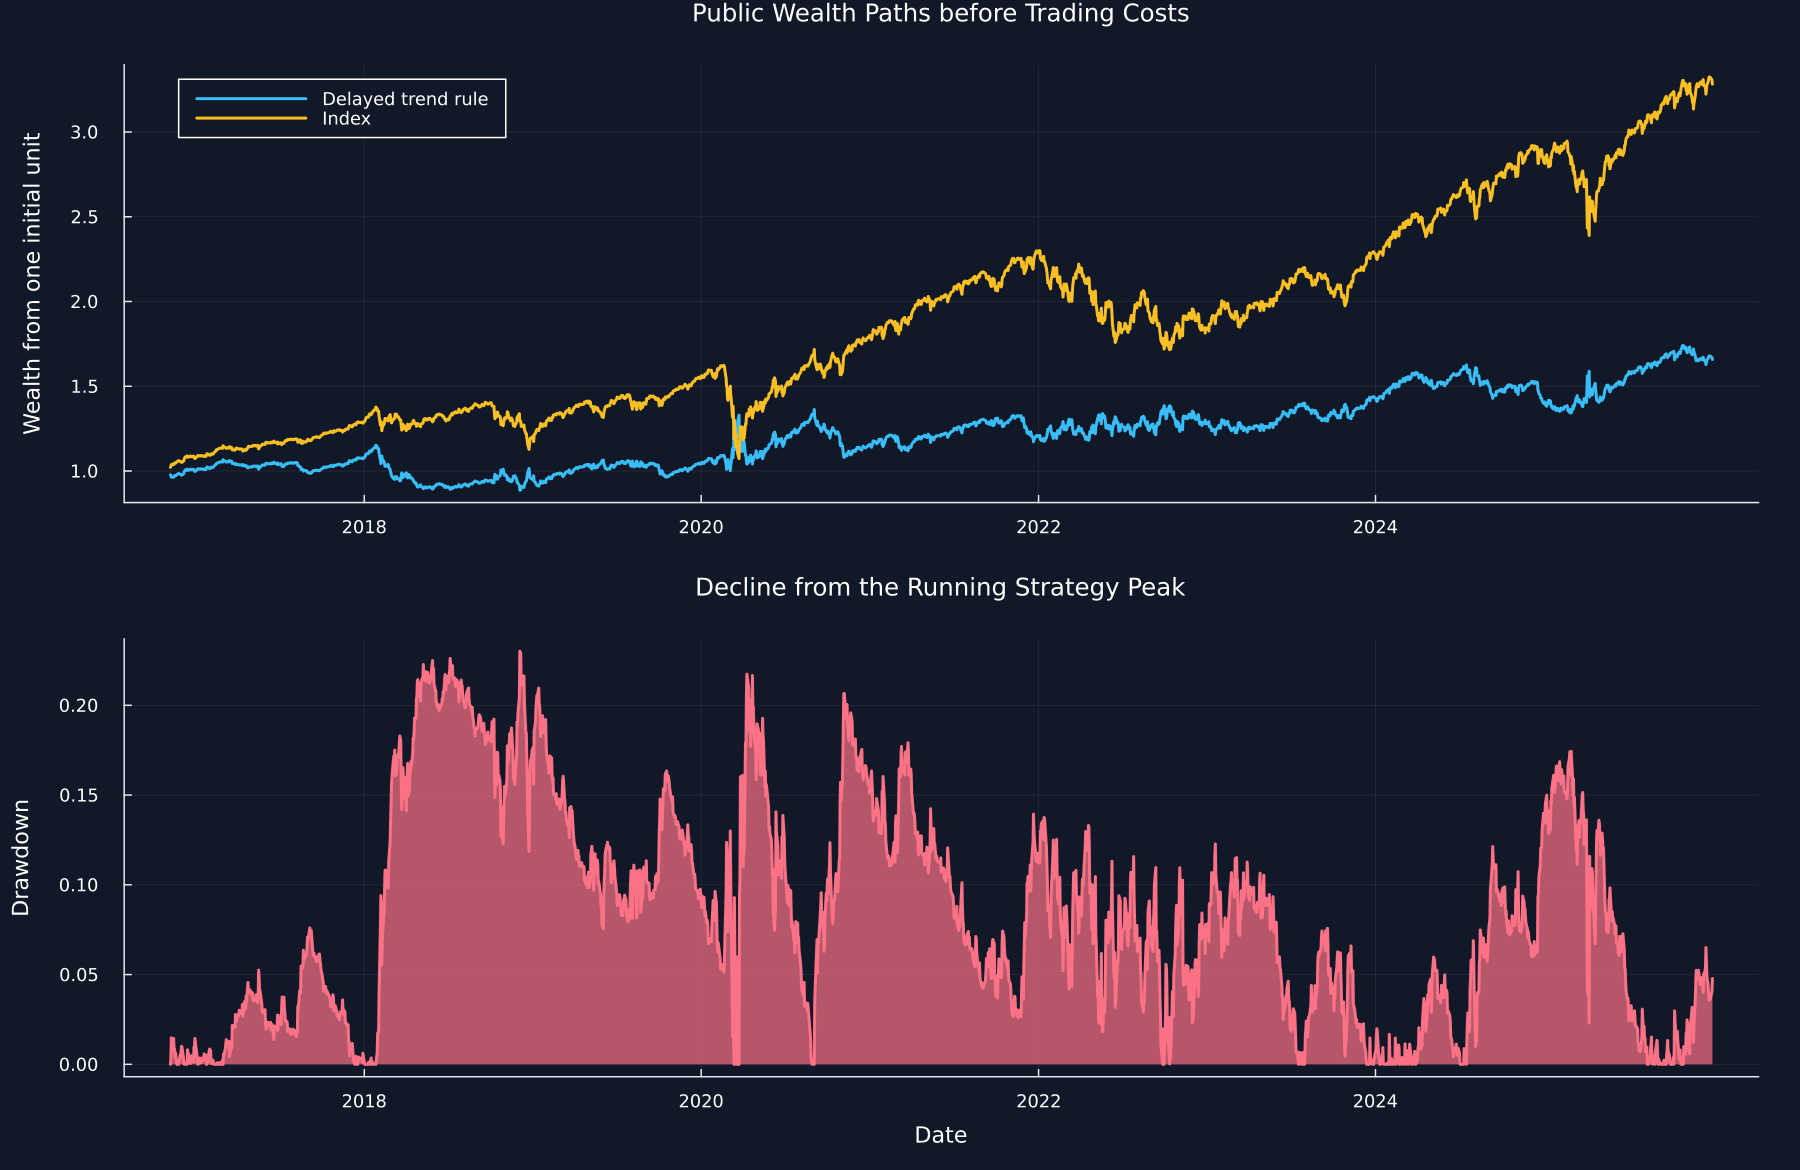

In [2]:
public_performance_summary = DataFrame("Quantity"=>["Price observations","Strategy-return observations","First strategy date","Last strategy date","Elapsed years","Ending strategy wealth","Ending index wealth","Annualized strategy return","Annualized index return","Annualized strategy Sharpe","Largest path drawdown"],"Value"=>Any[length(prices),length(strategy_returns),string(first(strategy_dates)),string(last(strategy_dates)),elapsed_years,last(strategy_wealth),last(index_wealth),last(strategy_wealth)^(1/elapsed_years)-1,last(index_wealth)^(1/elapsed_years)-1,sharpe_ratio(strategy_returns)*sqrt(252.),maximum(drawdown_path)])
strategy_data_provenance = DataFrame("Field"=>["Series","Provider","Source","Rule","Position delay"],"Value"=>["S&P 500","Federal Reserve Bank of St. Louis",data_url,"Sign of the five-day minus thirty-day exponential moving average","One observed day"])
table(strategy_data_provenance,"strategy_data_provenance","Public observations used for the performance-risk study.")
table(public_performance_summary,"public_performance_summary","Public strategy and index performance before trading costs.")
p1 = plot(Dates.value.(strategy_dates),strategy_wealth;color=palette.cyan,label="Delayed trend rule",ylabel="Wealth from one initial unit",title="Public Wealth Paths before Trading Costs",legend=:topleft,xticks=date_ticks(strategy_dates))
plot!(p1,Dates.value.(strategy_dates),index_wealth;color=palette.amber,label="Index")
p2 = plot(Dates.value.(strategy_dates),drawdown_path;fillrange=0,fillalpha=.7,color=palette.rose,label="",title="Decline from the Running Strategy Peak",xlabel="Date",ylabel="Drawdown",xticks=date_ticks(strategy_dates))
save_figure(plot(p1,p2;layout=(2,1),size=(1200,780)),paths,"public_wealth_drawdown")


## Measuring concentration across bets

Weighted holding time and normalized concentration summarize the shape of a backtest:

$$
\overline H=\frac{\sum_{i=1}^{B}w_iH_i}{\sum_{i=1}^{B}w_i},
\qquad
HHI_N=\frac{\sum_{i=1}^{B}\omega_i^2-B^{-1}}{1-B^{-1}},
\qquad
\omega_i=\frac{x_i}{\sum_{j=1}^{B}x_j}.
$$

Here, $B$ is the number of completed position pieces, $H_i$ is the holding time of piece $i$, $w_i$ is the closed position amount, $\overline H$ is the weighted average holding time, $x_i$ is the return or count used in a concentration calculation, $\omega_i$ is its normalized share, and $HHI_N$ is normalized concentration.

Row,Quantity,Value
,String,Float64
1,Bet-ending dates,84.0
2,Compounded sign runs,84.0
3,Bets per year,9.18318
4,Long bets,42.0
5,Short bets,42.0
6,Weighted holding period in days,39.8554
7,Positive-return concentration,0.0011719
8,Negative-return concentration,0.00134059
9,Monthly-count concentration,3.22575e-5


Row,End date,Side,Bet return
,Date,Float64,Float64
1,2020-09-11,1.0,0.209782
2,2025-11-17,1.0,0.199895
3,2024-04-15,1.0,0.159378
4,2021-09-17,1.0,0.137011
5,2019-05-10,1.0,0.109827
6,2023-08-11,1.0,0.108307
7,2017-03-24,1.0,0.0835406
8,2021-03-04,1.0,0.0735005
9,2018-02-05,1.0,0.0717294


Row,End date,Holding days,Closed position amount
,Date,Float64,Float64
1,2016-11-10,3.0,1.0
2,2017-03-27,137.0,1.0
3,2017-03-29,2.0,1.0
4,2017-04-13,15.0,1.0
5,2017-04-25,12.0,1.0
6,2017-07-07,73.0,1.0
7,2017-07-10,3.0,1.0
8,2017-08-14,35.0,1.0
9,2017-08-15,1.0,1.0


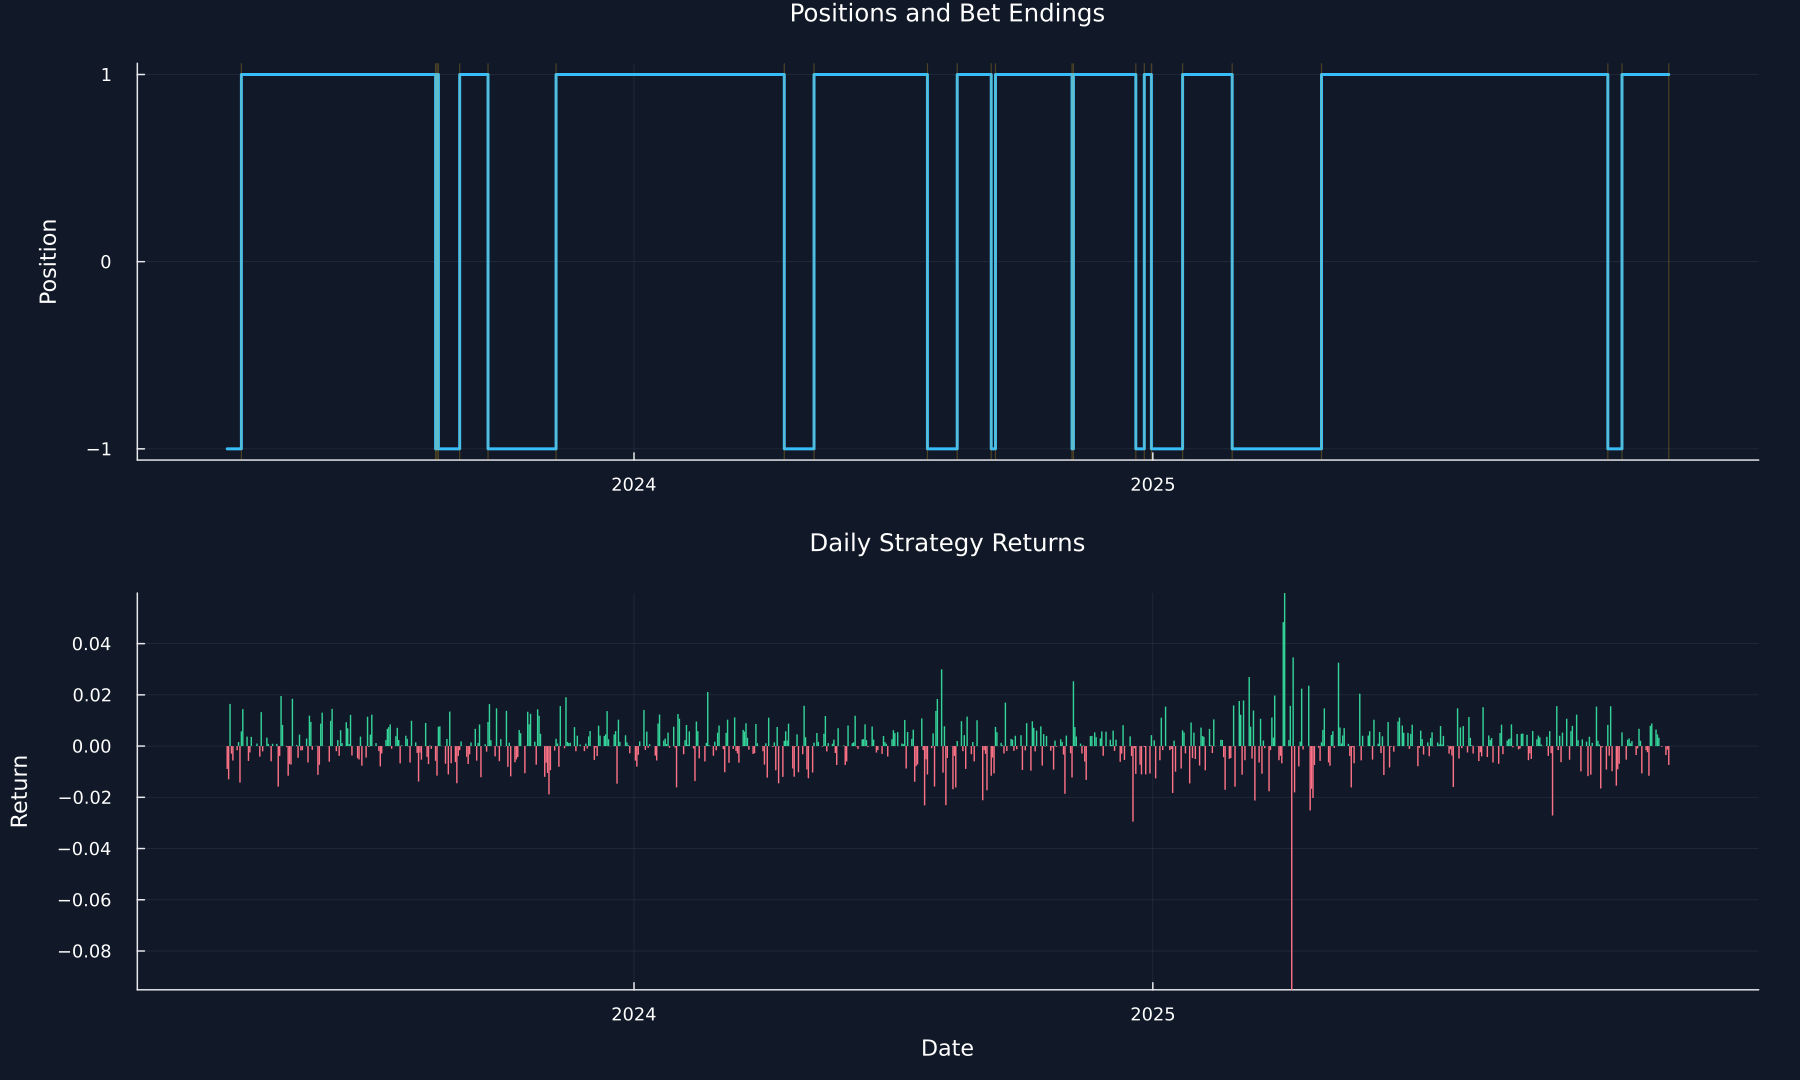

In [3]:
public_bet_dates = bet_timing(strategy_dates,target_positions)
holding = calculate_holding_period(strategy_dates,target_positions)
mean_holding_period = holding.mean_holding_period
concentration = calculate_hhi_concentration(strategy_dates,strategy_returns)
bet_summary = DataFrame("Quantity"=>["Bet-ending dates","Compounded sign runs","Bets per year","Long bets","Short bets","Weighted holding period in days","Positive-return concentration","Negative-return concentration","Monthly-count concentration"],"Value"=>[length(public_bet_dates),nrow(public_bets),nrow(public_bets)/elapsed_years,sum(public_bets.Side.>0),sum(public_bets.Side.<0),mean_holding_period,concentration.positive,concentration.negative,concentration.time])
leading_bets = public_bets[sortperm(abs.(public_bets[!,"Bet return"]);rev=true)[1:15],:]
holding_table = copy(holding.holding_periods)
rename!(holding_table,["End date","Holding days","Closed position amount"])
table(bet_summary,"public_bet_summary","Bet frequency, holding period, and concentration for the public rule.")
table(leading_bets,"largest_public_bets","The fifteen public bets with the largest absolute compounded returns.")
table(holding_table,"public_holding_detail","Closed position pieces used in the weighted holding-period calculation.")
save_data(DataFrame(date=public_bet_dates),paths,"bet_ending_dates")
recent = length(strategy_dates)-699:length(strategy_dates)
recent_dates = strategy_dates[recent]
p1 = plot(Dates.value.(recent_dates),target_positions[recent];seriestype=:steppost,color=palette.cyan,label="",ylabel="Position",title="Positions and Bet Endings",yticks=[-1,0,1],xticks=date_ticks(recent_dates;step=1))
for date in intersect(public_bet_dates,recent_dates)
    vline!(p1,[Dates.value(date)];color=palette.amber,alpha=.25,linewidth=.8,label="")
end
p2 = bar(Dates.value.(recent_dates),strategy_returns[recent];bar_width=1,color=ifelse.(strategy_returns[recent].>=0,palette.green,palette.rose),linealpha=0,label="",title="Daily Strategy Returns",xlabel="Date",ylabel="Return",xticks=date_ticks(recent_dates;step=1))
save_figure(plot(p1,p2;layout=(2,1),link=:x,size=(1200,720)),paths,"public_positions_bet_timing")


## Measuring drawdown depth and duration

Maximum drawdown and an empirical conditional expected drawdown are defined by:

$$
MDD_T=\max_{1\leq t\leq T}D_t,
\qquad
CED_{\alpha,h}=\frac{1}{1-\alpha}\int_{\alpha}^{1}Q_u\!\left(MDD_h\right)du.
$$

Here, $D_t$ is the drawdown at time $t$, $MDD_T$ is the largest drawdown over the complete horizon of $T$ observations, $h$ is a rolling measurement horizon, $MDD_h$ is the distribution of maximum drawdowns across those windows, $Q_u$ is its quantile at probability $u$, $\alpha$ is the tail threshold, and $CED_{\alpha,h}$ is the average of the worst $1-\alpha$ share of rolling maximum drawdowns.

Row,Peak date,Episode drawdown,Time under water in years
,Date,Float64,Float64
1,2018-01-26,0.230161,2.12183
2,2020-03-23,0.217366,0.429843
3,2020-09-02,0.206639,2.06434
4,2024-07-16,0.174378,1.0705
5,2022-09-30,0.122729,0.793977
6,2020-03-12,0.0928712,0.00273785
7,2017-03-01,0.0760506,0.780287
8,2023-07-31,0.0757783,0.366872
9,2025-10-28,0.0650647,0.175222


Row,Horizon,Tail level,Conditional expected drawdown
,Int64,Float64,Float64
1,20,0.9,0.103781
2,20,0.95,0.121753
3,20,0.99,0.175595
4,60,0.9,0.167508
5,60,0.95,0.200004
6,60,0.99,0.217366
7,120,0.9,0.216401
8,120,0.95,0.220645
9,120,0.99,0.225453


Row,Quantity,Value
,String,Float64
1,Largest path drawdown,0.230161
2,Drawdown episodes,54.0
3,Largest episode drawdown,0.230161
4,Longest time under water in years,2.12183
5,Sixty-day CED at 90 percent,0.167508
6,Sixty-day CED at 95 percent,0.200004
7,Sixty-day CED at 99 percent,0.217366


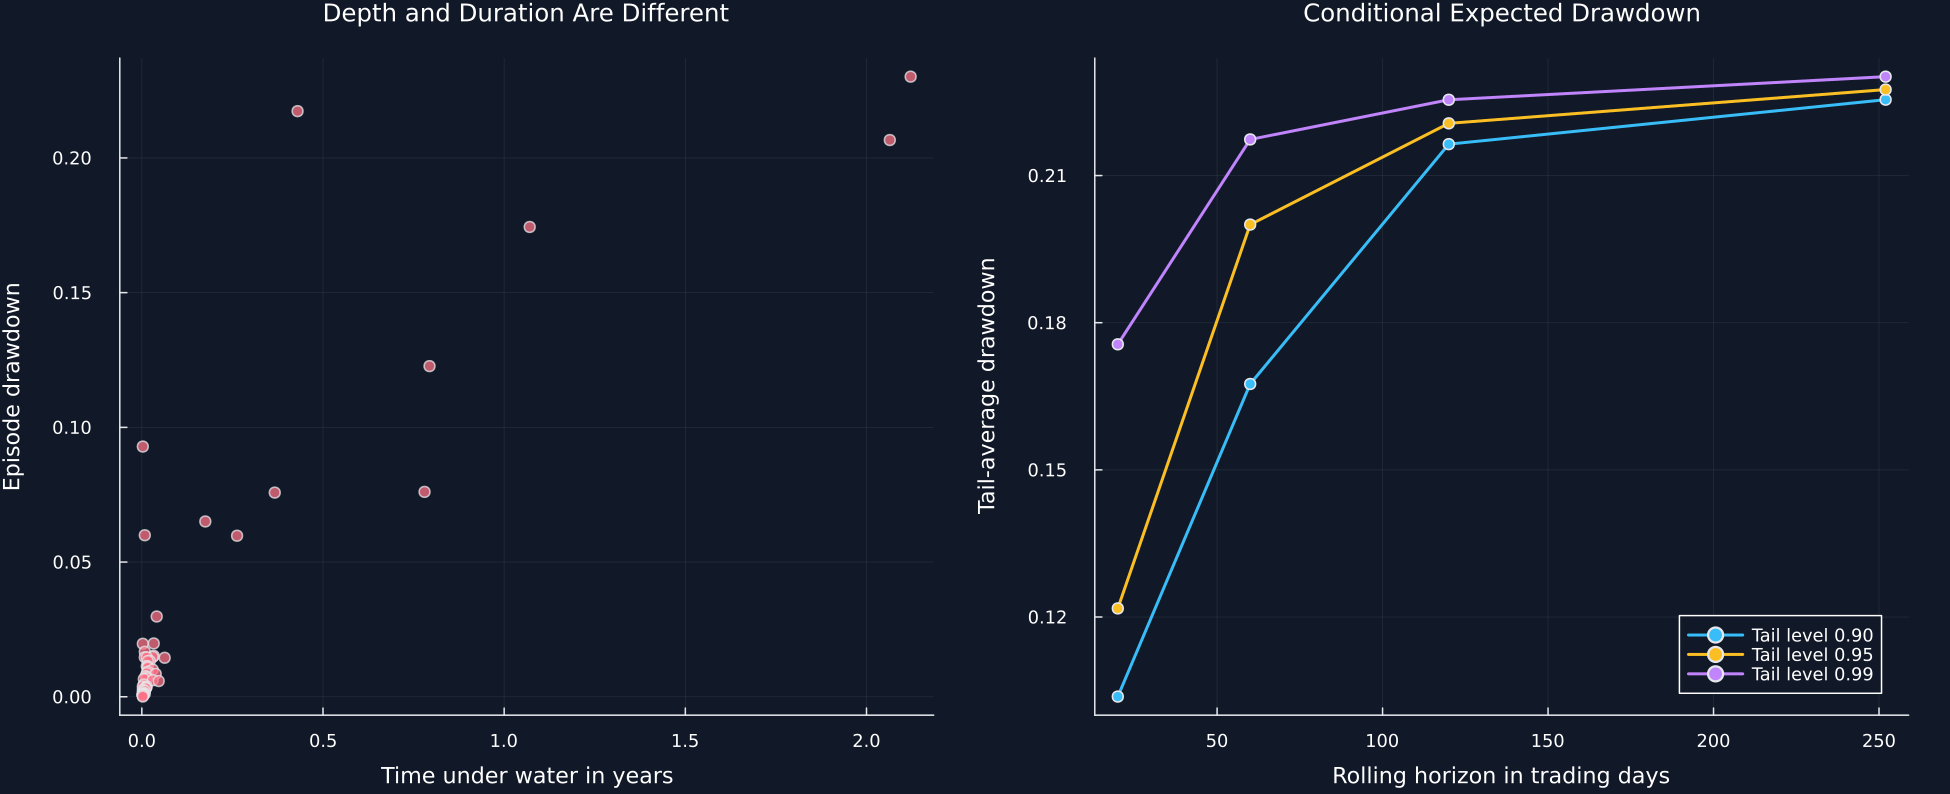

In [4]:
episodes = compute_drawdowns_time_under_water(strategy_dates,strategy_wealth)
drawdown_episode_table = DataFrame("Peak date"=>episodes.start,"Episode drawdown"=>episodes.drawdown,"Time under water in years"=>episodes.time_under_water)
sort!(drawdown_episode_table,"Episode drawdown";rev=true)
ced_rows = [(Horizon=horizon,level=alpha,ced=conditional_expected_drawdown(strategy_returns,horizon,alpha)) for horizon in [20,60,120,252] for alpha in [.90,.95,.99]]
ced_sensitivity = DataFrame(ced_rows)
rename!(ced_sensitivity,["Horizon","Tail level","Conditional expected drawdown"])
drawdown_summary = DataFrame("Quantity"=>["Largest path drawdown","Drawdown episodes","Largest episode drawdown","Longest time under water in years","Sixty-day CED at 90 percent","Sixty-day CED at 95 percent","Sixty-day CED at 99 percent"],"Value"=>[maximum(drawdown_path),length(episodes.drawdown),maximum(episodes.drawdown),maximum(episodes.time_under_water),[conditional_expected_drawdown(strategy_returns,60,alpha) for alpha in [.90,.95,.99]]...])
table(drawdown_episode_table,"drawdown_episodes","Public drawdown episodes and time under water.")
table(ced_sensitivity,"ced_sensitivity","Conditional expected drawdown across horizons and tail levels.")
table(drawdown_summary,"drawdown_summary","Drawdown summary for the public strategy.")
p1 = scatter(drawdown_episode_table[!,"Time under water in years"],drawdown_episode_table[!,"Episode drawdown"];color=palette.rose,alpha=.75,label="",xlabel="Time under water in years",ylabel="Episode drawdown",title="Depth and Duration Are Different")
p2 = plot(;xlabel="Rolling horizon in trading days",ylabel="Tail-average drawdown",title="Conditional Expected Drawdown",legend=:bottomright)
for (alpha,color) in zip([.90,.95,.99],[palette.cyan,palette.amber,violet])
    subset = ced_sensitivity[ced_sensitivity[!,"Tail level"].==alpha,:]
    plot!(p2,subset.Horizon,subset[!,"Conditional expected drawdown"];marker=:circle,color,label=@sprintf("Tail level %.2f",alpha))
end
save_figure(plot(p1,p2;layout=(1,2),size=(1300,530)),paths,"drawdown_episode_ced_sensitivity")


## Repeated-History Stability

Repeated public-data block samples compare the relative sampling spread of two drawdown estimates:

$$
CV(\widehat R)=\frac{\operatorname{sd}(\widehat R_1,\ldots,\widehat R_M)}{\operatorname{mean}(\widehat R_1,\ldots,\widehat R_M)}.
$$

Here, $\widehat R_m$ is a drawdown estimate from repeated history $m$, $M$ is the number of repeated histories, $\operatorname{sd}$ is their sample standard deviation, $\operatorname{mean}$ is their average, and $CV$ is the coefficient of variation. Circular blocks retain short runs of the public returns while producing the repeated histories that one observed path cannot supply.

Row,Estimate,Repeated histories,History length,Block length,Mean,Standard deviation,Coefficient of variation,Fifth percentile,Ninety-fifth percentile
,String,Int64,Int64,Int64,Float64,Float64,Float64,Float64,Float64
1,Maximum drawdown,300,500,20,0.194876,0.0714951,0.366874,0.10205,0.335777
2,Conditional expected drawdown,300,500,20,0.154618,0.0441388,0.28547,0.0955782,0.242112


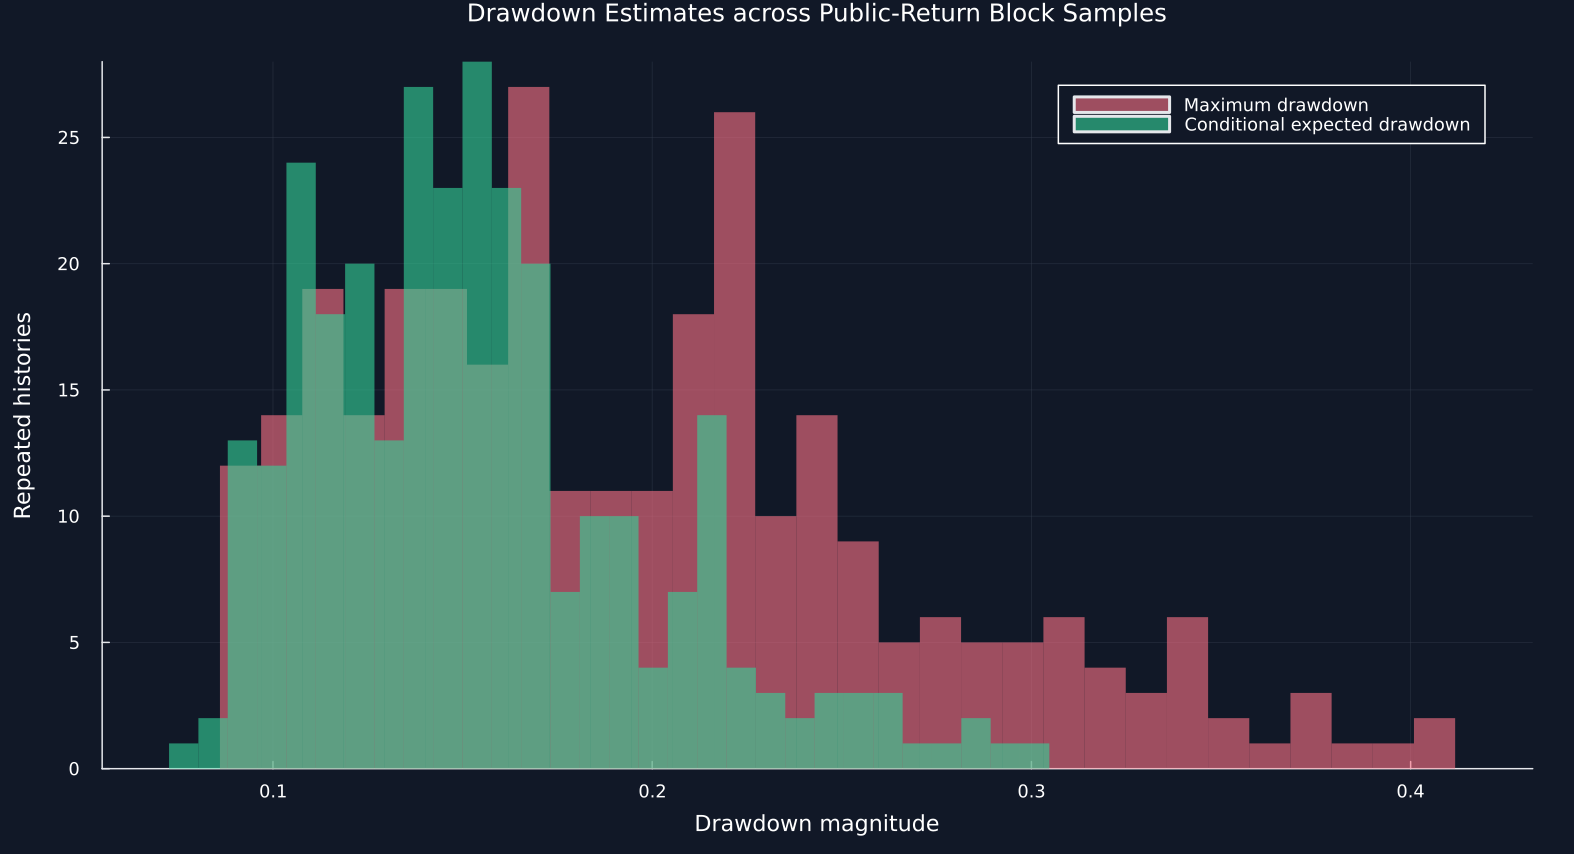

In [5]:
bootstrap_positions = Int.(primitive("drawdown_bootstrap.csv"))
repeated_maximum_drawdowns,repeated_ced = zeros(300),zeros(300)
for repetition in 1:300
    sample = strategy_returns[bootstrap_positions[:,repetition]]
    repeated_maximum_drawdowns[repetition] = maximum_drawdown(sample)
    repeated_ced[repetition] = conditional_expected_drawdown(sample,60,.95)
end
samples = [repeated_maximum_drawdowns,repeated_ced]
resampled_drawdown_summary = DataFrame("Estimate"=>["Maximum drawdown","Conditional expected drawdown"],"Repeated histories"=>[300,300],"History length"=>[500,500],"Block length"=>[20,20],"Mean"=>mean.(samples),"Standard deviation"=>std.(samples),"Coefficient of variation"=>std.(samples)./mean.(samples),"Fifth percentile"=>[quantile(values,.05) for values in samples],"Ninety-fifth percentile"=>[quantile(values,.95) for values in samples])
table(resampled_drawdown_summary,"resampled_drawdown_summary","Sampling spread across circular block histories drawn from public returns.")
save_data(DataFrame(sample=1:300,maximum_drawdown=repeated_maximum_drawdowns,ced=repeated_ced),paths,"drawdown_resamples")
figure = plot(;xlabel="Drawdown magnitude",ylabel="Repeated histories",title="Drawdown Estimates across Public-Return Block Samples",legend=:topright,size=(1050,570))
for (values,color,label,stem) in zip(samples,[palette.rose,palette.green],["Maximum drawdown","Conditional expected drawdown"],["maximum_drawdown_histogram","ced_histogram"])
    edges,counts = drawdown_histogram(values)
    save_data(DataFrame(left=edges[1:end-1],right=edges[2:end],count=counts),paths,stem)
    bar!(figure,(edges[1:end-1].+edges[2:end])./2,counts;bar_width=diff(edges),color,alpha=.6,linealpha=0,label)
end
save_figure(figure,paths,"resampled_drawdown_distributions")


## Linking trade precision to strategy risk

A two-outcome strategy has an annualized Sharpe ratio determined by its win chance, payoffs, and betting frequency:

$$
SR(p,n,\pi_-,\pi_+)=\frac{(\pi_+-\pi_-)p+\pi_-}{(\pi_+-\pi_-)\sqrt{p(1-p)}}\sqrt n.
$$

Here, $p$ is the probability of a profitable bet, $n$ is the number of bets per year, $\pi_+>0$ is the average profitable outcome, $\pi_-<0$ is the average losing outcome, and $SR$ is the annualized Sharpe ratio under independent two-outcome bets.

Row,Quantity,Value
,String,Float64
1,Bets,84.0
2,Bets per year,9.18318
3,Profitable share,0.380952
4,Average profit,0.0530011
5,Average loss,-0.0209422
6,Two-outcome annual Sharpe,0.609871
7,Daily-return annual Sharpe,0.391955
8,Frequency needed for target Sharpe one,24.6898


Row,Target annual Sharpe,Required profitable share,Observed profitable share,Approximate probability below requirement
,Float64,Float64,Float64,Float64
1,0.0,0.28322,0.380952,0.0325544
2,0.5,0.362539,0.380952,0.364101
3,1.0,0.447297,0.380952,0.894737
4,1.5,0.53026,0.380952,0.997583
5,2.0,0.605747,0.380952,0.999989


Row,Bets per year,Target annual Sharpe,Required profitable share
,Int64,Float64,Float64
1,5,0.5,0.392404
2,5,1.0,0.506806
3,5,1.5,0.610358
4,5,2.0,0.695015
5,10,0.5,0.359072
6,10,1.0,0.440199
7,10,1.5,0.520197
8,10,2.0,0.59383
9,25,0.5,0.33025


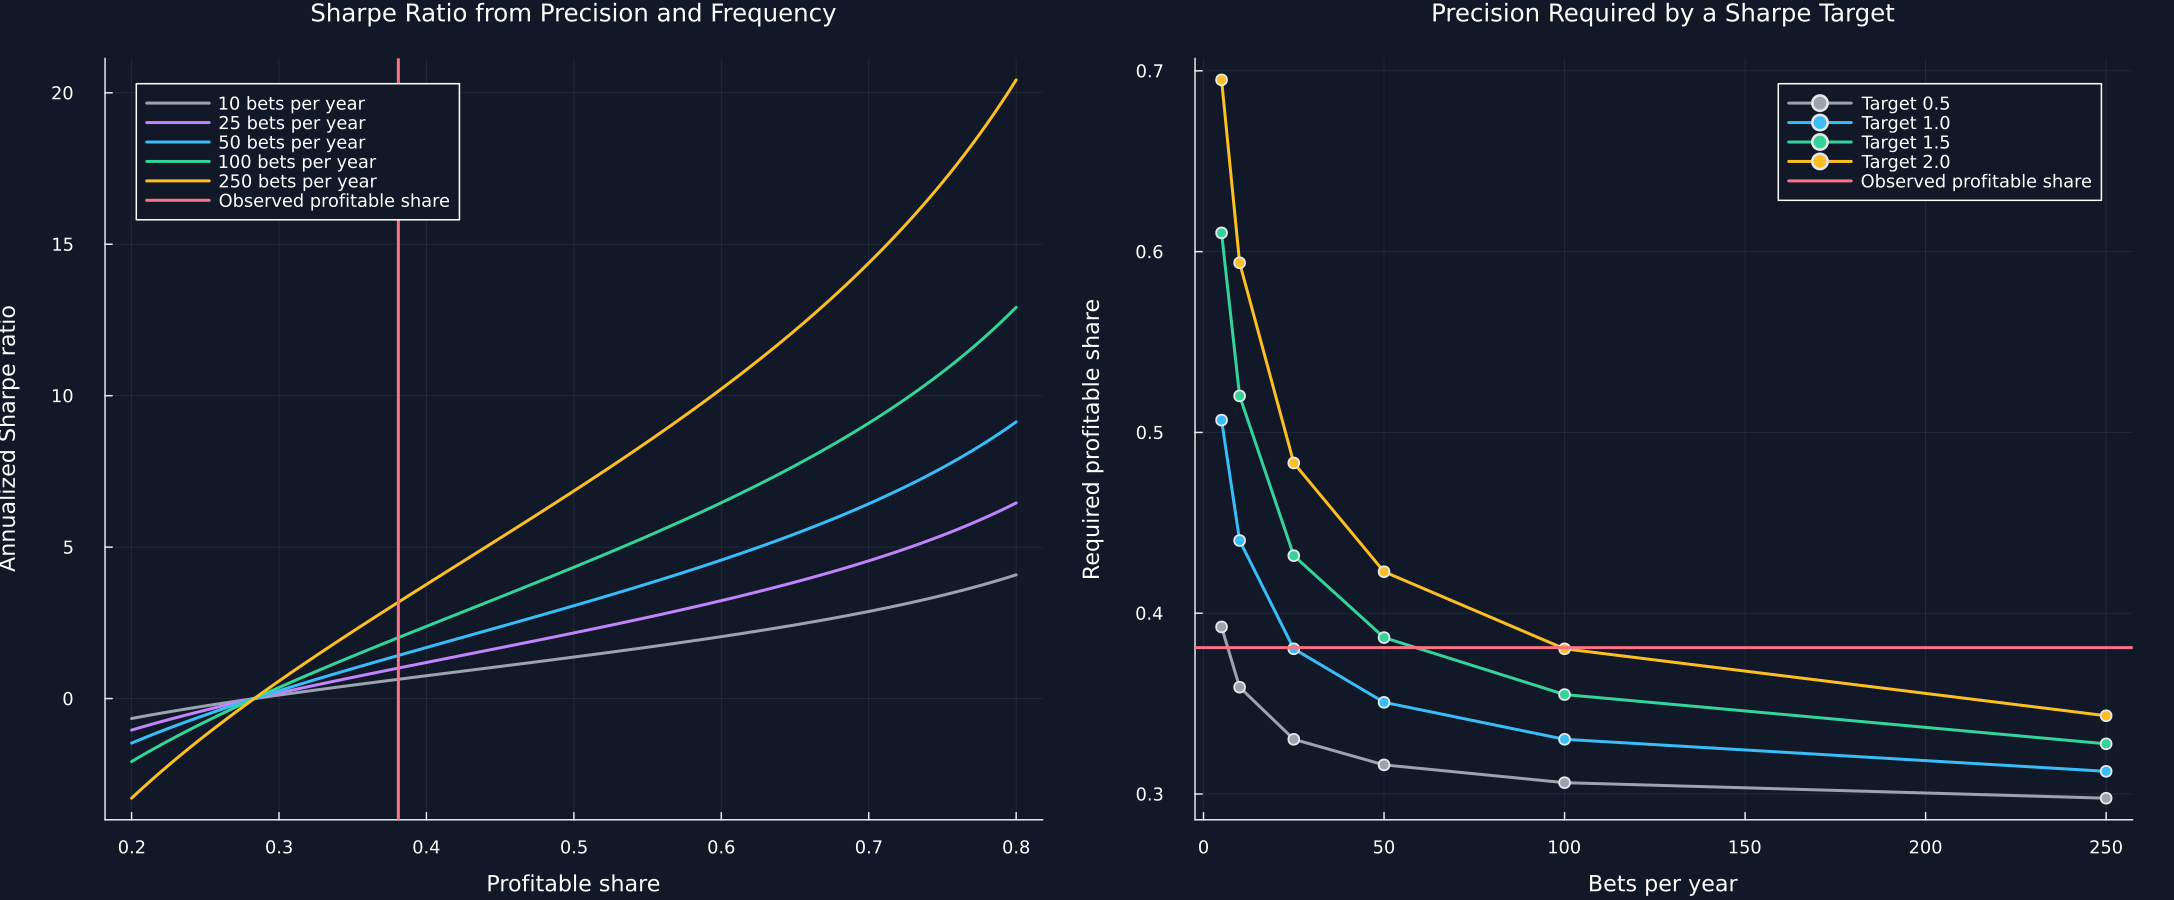

In [6]:
bet_returns = public_bets[!,"Bet return"]
positive_bets,negative_bets = bet_returns[bet_returns.>0],bet_returns[bet_returns.<=0]
observed_precision = length(positive_bets)/length(bet_returns)
average_profit,average_loss = mean(positive_bets),mean(negative_bets)
observed_frequency = length(bet_returns)/elapsed_years
binary_sharpe = binomial_sharpe_ratio(average_loss,average_profit,observed_frequency,observed_precision)
targets = [0.,.5,1.,1.5,2.]
required = [implied_precision(average_loss,average_profit,observed_frequency,target) for target in targets]
standard_error = sqrt(observed_precision*(1-observed_precision)/length(bet_returns))
public_strategy_risk = DataFrame("Target annual Sharpe"=>targets,"Required profitable share"=>required,"Observed profitable share"=>fill(observed_precision,5),"Approximate probability below requirement"=>cdf.(Normal(),(required.-observed_precision)./standard_error))
strategy_risk_summary = DataFrame("Quantity"=>["Bets","Bets per year","Profitable share","Average profit","Average loss","Two-outcome annual Sharpe","Daily-return annual Sharpe","Frequency needed for target Sharpe one"],"Value"=>[length(bet_returns),observed_frequency,observed_precision,average_profit,average_loss,binary_sharpe,sharpe_ratio(strategy_returns)*sqrt(252.),bin_frequency(average_loss,average_profit,observed_precision,1.)])
precision_sensitivity = DataFrame([(frequency=frequency,target=target,precision=implied_precision(average_loss,average_profit,frequency,target)) for frequency in [5,10,25,50,100,250] for target in [.5,1.,1.5,2.]])
rename!(precision_sensitivity,["Bets per year","Target annual Sharpe","Required profitable share"])
table(strategy_risk_summary,"strategy_risk_summary","Two-outcome summary for the public strategy.")
table(public_strategy_risk,"public_strategy_risk","Required precision and approximate lower-tail risk at several Sharpe targets.")
table(precision_sensitivity,"precision_sensitivity","Required profitable shares as frequency and the Sharpe target change.")
precision_axis = collect(range(.20,.80;length=280))
curve_rows = NamedTuple[]
p1 = plot(;xlabel="Profitable share",ylabel="Annualized Sharpe ratio",title="Sharpe Ratio from Precision and Frequency",legend=:topleft)
for (frequency,color) in zip([10,25,50,100,250],[muted,violet,palette.cyan,palette.green,palette.amber])
    values = [binomial_sharpe_ratio(average_loss,average_profit,frequency,probability) for probability in precision_axis]
    plot!(p1,precision_axis,values;color,label=string(frequency)*" bets per year")
    append!(curve_rows,[(frequency=frequency,probability=probability,sharpe=value) for (probability,value) in zip(precision_axis,values)])
end
vline!(p1,[observed_precision];color=palette.rose,label="Observed profitable share")
save_data(DataFrame(curve_rows),paths,"precision_frequency_curves")
p2 = plot(;xlabel="Bets per year",ylabel="Required profitable share",title="Precision Required by a Sharpe Target",legend=:topright)
for (target,color) in zip([.5,1.,1.5,2.],[muted,palette.cyan,palette.green,palette.amber])
    subset = precision_sensitivity[precision_sensitivity[!,"Target annual Sharpe"].==target,:]
    plot!(p2,subset[!,"Bets per year"],subset[!,"Required profitable share"];marker=:circle,color,label=@sprintf("Target %.1f",target))
end
hline!(p2,[observed_precision];color=palette.rose,label="Observed profitable share")
save_figure(plot(p1,p2;layout=(1,2),size=(1450,600)),paths,"strategy_risk_precision_frequency")


## Preliminary Checks with Known Inputs

A two-component normal mixture supplies known component means, spreads, and mixture weight for a direct calculation check:

$$
X\sim p\,\mathcal N(\mu_+,\sigma_+^2)+(1-p)\,\mathcal N(\mu_-,\sigma_-^2).
$$

Here, $X$ is a generated bet outcome, $p$ is the probability of drawing from the profitable component, $\mu_+$ and $\mu_-$ are the component means, and $\sigma_+$ and $\sigma_-$ are their standard deviations. The complete generation code is shown because the population component values must be known for this check.

In [7]:
function mixture(name,count)
    values = primitive("mixture_"*name*".csv")
    return mix_gaussians(10.,-10.,1.,1.,count/1000,1000;normal_draws=(values[1:count,1],values[count+1:end,1]),permutation=Int.(values[:,2]))
end
mixture_half,mixture_biased = mixture("half",500),mixture("biased",800)
mixture_reproduction = DataFrame("Mixture weight"=>[.5,.8],"Observations"=>[1000,1000],"Population mean"=>[0.,6.],"Sample mean"=>mean.([mixture_half,mixture_biased]),"Sample standard deviation"=>std.([mixture_half,mixture_biased]))
preliminary_strategy_reproduction = DataFrame("Quantity"=>["Target annual Sharpe","Bets per year","Profit amount","Loss magnitude","Observed profitable share","Required share with a negative loss outcome","Required share with a positive loss magnitude","Sharpe at observed share"],"Value"=>[2.,52.,.04,.02,.60,implied_precision(-.02,.04,52,2.),implied_precision(.02,.04,52,2.),binomial_sharpe_ratio(-.02,.04,52,.60)])
controlled_dates = Date(2020,1,1).+Day.(0:7)
controlled_bet_dates = bet_timing(controlled_dates,[0,1,1,0,-1,-1,1,0])
controlled_holding_mean = calculate_holding_period(controlled_dates[1:4],[0,1,1,0]).mean_holding_period
controlled_drawdowns = compute_drawdowns_time_under_water(Date(2020,1,1).+Day.(0:9),[10,9,8,10,11,10,12,11,10,12];dollars=true)
controlled_backtest_checks = DataFrame("Quantity"=>["Bet-ending dates","Mean holding days","Equal-return concentration","Single-return concentration","Drawdown episodes","Largest dollar drawdown","Longest controlled time under water in days"],"Value"=>[length(controlled_bet_dates),controlled_holding_mean,calculate_hhi([1,1,1,1]),calculate_hhi([10,0,0,0]),length(controlled_drawdowns.drawdown),maximum(controlled_drawdowns.drawdown),maximum(controlled_drawdowns.time_under_water)*365.25])
table(mixture_reproduction,"mixture_reproduction","Known-input mixture checks retained from the released tests.")
table(preliminary_strategy_reproduction,"preliminary_strategy_reproduction","Sign-sensitive reproduction of the preliminary strategy-risk example.")
table(controlled_backtest_checks,"controlled_backtest_checks","Controlled checks for bet timing, holding time, concentration, and drawdowns.")
save_data(DataFrame(half=mixture_half,biased=mixture_biased),paths,"gaussian_mixture_samples")
save_data(DataFrame([(probability=p,profit=u,loss=d,variance=target_sharpe_ratio_symbolic(p,u,d)) for p in [0.,.1,.5,.9,1.] for u in [-.01,0.,.04] for d in [-.02,.01]]),paths,"variance_polynomial");


Row,Mixture weight,Observations,Population mean,Sample mean,Sample standard deviation
,Float64,Int64,Float64,Float64,Float64
1,0.5,1000,0.0,0.00706102,10.0644
2,0.8,1000,6.0,6.01381,8.05403


Row,Quantity,Value
,String,Float64
1,Target annual Sharpe,2.0
2,Bets per year,52.0
3,Profit amount,0.04
4,Loss magnitude,0.02
5,Observed profitable share,0.6
6,Required share with a negative loss outcome,0.471787
7,Required share with a positive loss magnitude,NaN
8,Sharpe at observed share,3.92523


Row,Quantity,Value
,String,Float64
1,Bet-ending dates,3.0
2,Mean holding days,2.0
3,Equal-return concentration,0.0
4,Single-return concentration,1.0
5,Drawdown episodes,3.0
6,Largest dollar drawdown,2.0
7,Longest controlled time under water in days,3.0


## Tests

In [8]:
@assert length(prices)==2330
@assert length(strategy_returns)==2300
@assert nrow(public_bets)==84
@assert isclose(elapsed_years,9.14715947980835)
@assert isclose(sharpe_ratio(strategy_returns)*sqrt(252.),.3919550723583464)
@assert length(public_bet_dates)==84
@assert isclose(mean_holding_period,39.855421686746986)
@assert Date(2020,1,4) in controlled_bet_dates
@assert Date(2020,1,7) in controlled_bet_dates
@assert Date(2020,1,8) in controlled_bet_dates
@assert isclose(controlled_holding_mean,2.)
@assert isclose(calculate_hhi([1,1,1,1]),0.)
@assert isclose(calculate_hhi([10,0,0,0]),1.)
@assert length(controlled_drawdowns.drawdown)==3
@assert isclose(first(controlled_drawdowns.drawdown),2.)
@assert isclose(first(controlled_drawdowns.time_under_water),3/365.25)
@assert 0<=conditional_expected_drawdown(strategy_returns,60,.95)<1
@assert conditional_expected_drawdown(fill(.001,200),20,.95)==0.
@assert size(resampled_drawdown_summary)==(2,9)
@assert resampled_drawdown_summary[2,"Coefficient of variation"]<resampled_drawdown_summary[1,"Coefficient of variation"]
@assert isclose(binomial_sharpe_ratio(-.01,.01,252,.5),0.)
@assert isclose(binomial_sharpe_ratio(-.01,.01,252,.6),3.2403703492039306)
@assert isclose(bin_frequency(-.01,.01,.6,3.2403703492039306),252.)
@assert isclose(implied_precision(-.01,.01,252,3.2396),.6;atol=1e-4)
@assert length(mixture_half)==1000
@assert length(mixture_biased)==1000
@assert isclose(mean(mixture_half),0.;atol=.5)
@assert isclose(mean(mixture_biased),6.;atol=.5)
@assert isclose(target_sharpe_ratio_symbolic(.6,.01,-.01),.6*.4*.02^2)
@assert issorted(public_strategy_risk[!,"Required profitable share"])
@assert isfile(joinpath(paths.figures,"public_wealth_drawdown.pdf"))
@assert isfile(joinpath(paths.figures,"public_positions_bet_timing.pdf"))
@assert isfile(joinpath(paths.figures,"drawdown_episode_ced_sensitivity.pdf"))
@assert isfile(joinpath(paths.figures,"resampled_drawdown_distributions.pdf"))
@assert isfile(joinpath(paths.figures,"strategy_risk_precision_frequency.pdf"))
table(DataFrame("Check"=>["Public file identity","Delayed public rule","Bet timing","Holding period","Concentration bounds","Drawdown episodes","Conditional expected drawdown","Repeated-history stability","Two-outcome Sharpe","Precision-frequency inverse","Known mixture moments","Symbolic variance"],"Status"=>fill("Pass",12)),"strategy_checks","Strategy-statistics checks.")


Row,Check,Status
,String,String
1,Public file identity,Pass
2,Delayed public rule,Pass
3,Bet timing,Pass
4,Holding period,Pass
5,Concentration bounds,Pass
6,Drawdown episodes,Pass
7,Conditional expected drawdown,Pass
8,Repeated-history stability,Pass
9,Two-outcome Sharpe,Pass
